# AIMLZG546 – Software Engineering for Machine Learning
## Assignment I – ML-Based Cross-Border Payment Route Selection

**Group No:** 65

| Sl. No | BITS ID | Name | Contribution (Qualitative) | % Contribution |
|---|---|---|---|---|
| 1 | 2025AE05773 | Mitesh Kapil | Problem formulation, requirement specification, GR4ML Business & Analytics Design Views | 25 |
| 2 | 2025AE05774 | Sayam Kansal | Dataset generation, Data Preparation View, data_prep.py, quality requirements | 25 |
| 3 | 2025AE05392 | Prashansa Gupta | Model training/evaluation (train.py), prediction service, notebook | 25 |
| 4 | 2025AF05050 | Udayasankar Gopalakrishnan | Architecture, microservices + event-driven implementation, demos, report | 25 |

This notebook accompanies the report `65.docx`. It runs the complete pipeline:
1. Data quality validation (GR4ML Data Preparation View)
2. Training & evaluation of the two prediction models (Analytics Design View – Prediction Goals 1 & 2)
3. The prescription/decision engine (Prescription Goal)
4. Starting the microservices + event broker and exercising the system end-to-end (Objective 2)

> Run from the `src/` directory. Only `pandas`, `numpy`, `scikit-learn`, `matplotlib`, `joblib`, `graphviz` are required; the services use the Python standard library.

## 1. Data loading and quality validation
Implements the *Validate* operator of the Data Preparation View: schema, types, duplicates, temporal consistency, missing values.

In [1]:
import json, pandas as pd
from data_prep import load_raw, validate, make_splits, FEATURES, CAT_FEATURES, NUM_FEATURES
df = load_raw("../data.csv")
print(df.shape); print(df.head(3).T)
report = validate(df)
print(json.dumps(report, indent=2))

(50000, 20)
                                                  0  ...                    2
transaction_id                           TXN_000001  ...           TXN_000003
timestamp                       2025-03-16T15:13:00  ...  2025-11-24T02:29:00
source_country                               Canada  ...            Australia
destination_country                           India  ...                India
source_currency                                 CAD  ...                  AUD
destination_currency                            INR  ...                  INR
amount                                      1323.74  ...               246.14
payment_type                                    P2P  ...                  P2P
hour_of_day                                      15  ...                    2
day_of_week                                       6  ...                    0
is_weekend                                        1  ...                    0
route_id                                    ROUTE_F 

In [2]:
train_df, val_df, test_df = make_splits(df)
print("Split sizes -> train:", len(train_df), " validation:", len(val_df), " test:", len(test_df))
print("Success rate per split:", round(train_df.payment_success.mean(),4), round(val_df.payment_success.mean(),4), round(test_df.payment_success.mean(),4))
print("\nFeatures used by the models (%d):" % len(FEATURES)); print(" categorical:", CAT_FEATURES); print(" numeric    :", NUM_FEATURES)

Split sizes -> train: 35000  validation: 7500  test: 7500
Success rate per split: 0.9133 0.9133 0.9132

Features used by the models (15):
 categorical: ['source_country', 'destination_country', 'source_currency', 'destination_currency', 'payment_type', 'route_id', 'sending_institution', 'receiving_institution']
 numeric    : ['amount', 'hour_of_day', 'day_of_week', 'is_weekend', 'route_cost', 'historical_route_success_rate', 'historical_avg_latency_seconds']


## 2. Exploratory look at the route catalogue
Each of the 6 candidate routes has fixed institutions, cost and historical performance. The decision engine scores all 6 for every payment.

In [3]:
cat = df.groupby("route_id").agg(sending=("sending_institution","first"), receiving=("receiving_institution","first"), cost=("route_cost","first"),
      hist_success=("historical_route_success_rate","first"), hist_latency_s=("historical_avg_latency_seconds","first"),
      actual_success=("payment_success","mean"), median_settle_s=("settlement_time_seconds","median"), n=("transaction_id","count"))
print(cat.round(3).to_string())
print("\nSuccess rate by route x destination country:")
print(df.groupby(["route_id","destination_country"]).payment_success.mean().unstack().round(3).to_string())

         sending receiving  cost  hist_success  hist_latency_s  actual_success  median_settle_s     n
route_id                                                                                             
ROUTE_A   Bank_A    Bank_X   1.5          0.95          3600.0           0.935           4246.0  8393
ROUTE_B   Bank_B    Bank_Y   5.0          0.99           300.0           0.978            336.0  8493
ROUTE_C   Bank_C    Bank_Z   0.5          0.85         86400.0           0.829          96398.0  8268
ROUTE_D   Bank_A    Bank_Y   2.0          0.92          7200.0           0.913           8063.0  8368
ROUTE_E   Bank_B    Bank_Z   3.5          0.97          1800.0           0.955           2016.0  8408
ROUTE_F   Bank_C    Bank_X   1.0          0.88         43200.0           0.866          48307.5  8070

Success rate by route x destination country:
destination_country  India  Mexico  Nigeria  Philippines
route_id                                                
ROUTE_A              0.9

## 3. Model training and evaluation (Prediction Goals 1 & 2)
`train.py` fits the preprocessing pipeline + two gradient-boosted models, tunes the classification threshold on the validation split, measures calibration and inference latency, and persists versioned artifacts.

=== Prediction Goal 1: payment_success (test set) ===
                                  roc_auc   brier  log_loss  balanced_accuracy  failure_recall  accuracy  precision  recall      f1
gbdt_classifier                    0.6980  0.0761    0.2746             0.6395          0.6790    0.6069     0.9516  0.6001  0.7360
logistic_baseline                  0.6994  0.0760    0.2745             0.6454          0.6605    0.6329     0.9513  0.6303  0.7582
majority_baseline                  0.5000  0.0868    1.1992             0.5000          0.0000    0.9132     0.9132  1.0000  0.9546
historical_success_rate_baseline   0.6831  0.0768       NaN                NaN             NaN       NaN        NaN     NaN     NaN
Confusion matrix [[TN,FP],[FN,TP]]: [[442, 209], [2739, 4110]] | tuned threshold: 0.91 | expected calibration error: 0.0057

=== Prediction Goal 2: settlement_time_seconds, completed payments (test set) ===
                             mae_seconds  rmse_seconds     r2  mae_minutes
gbdt

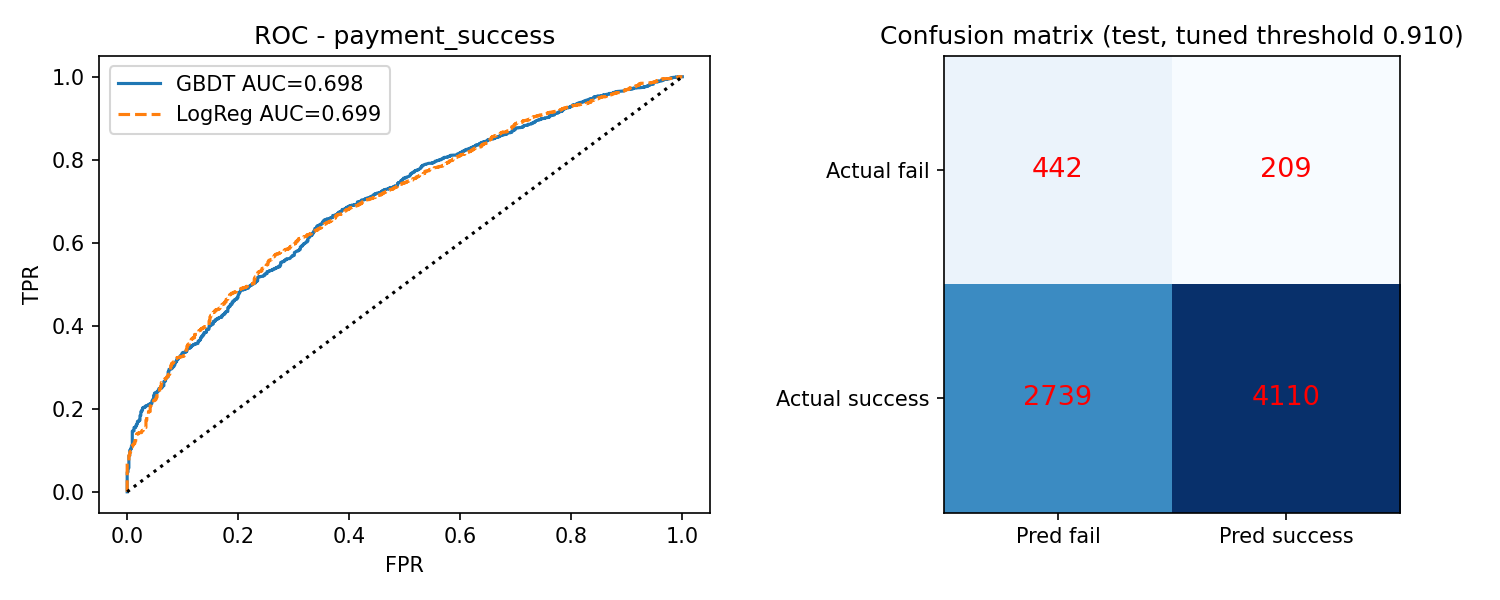

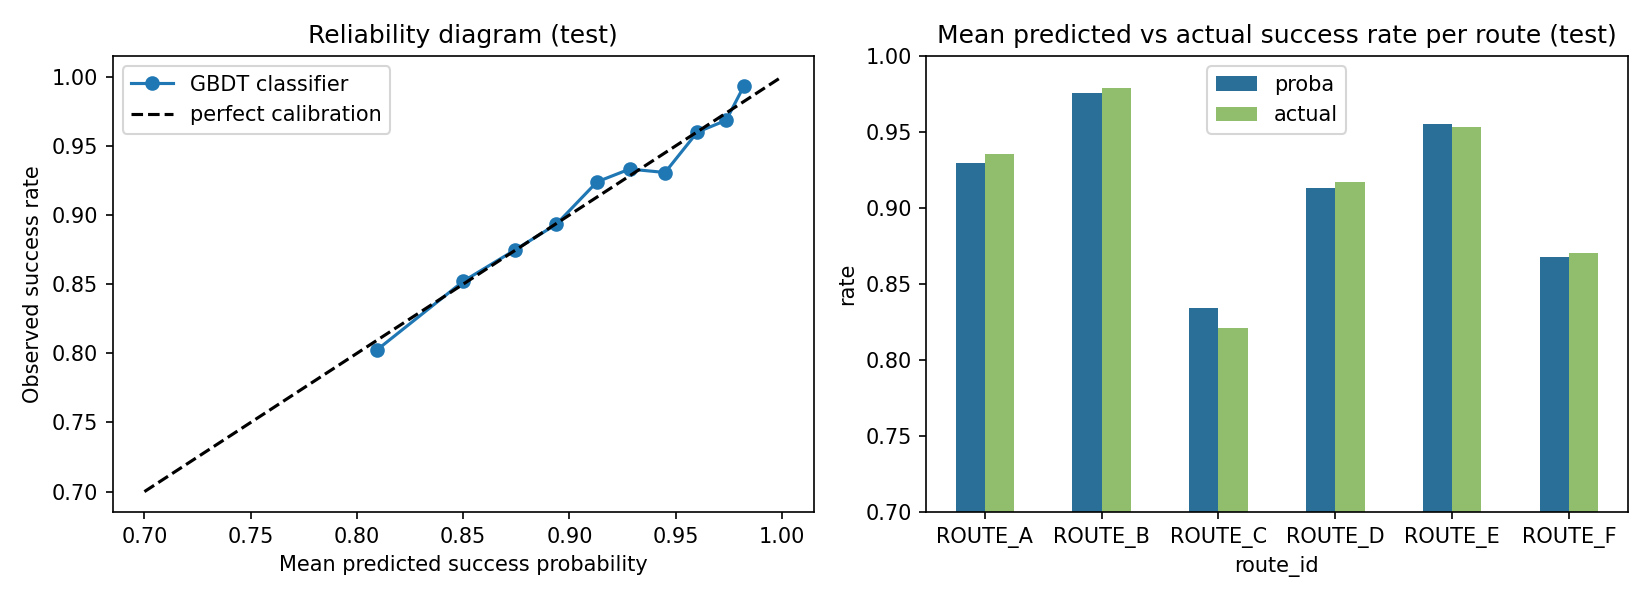

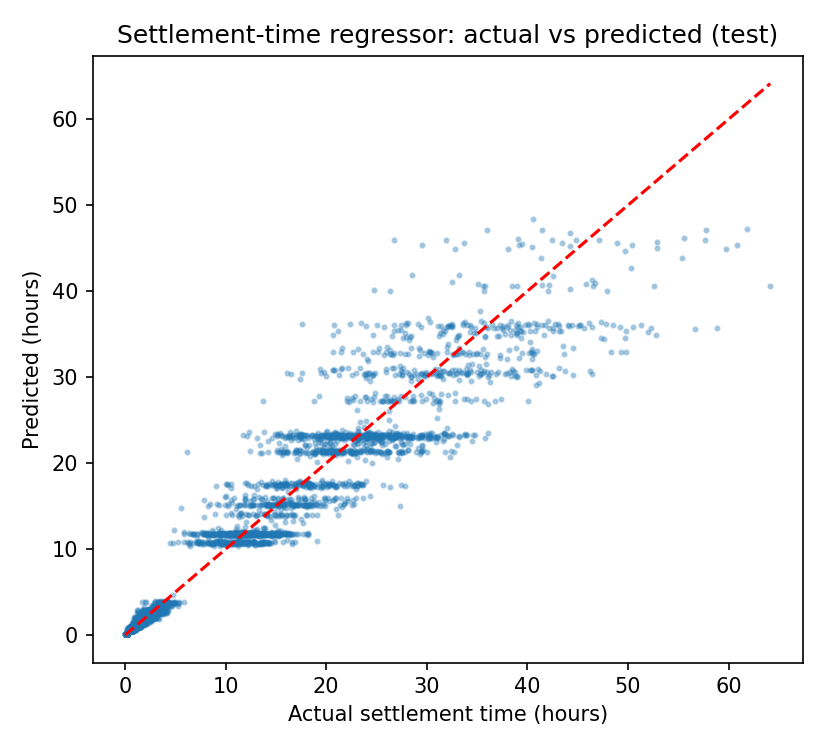

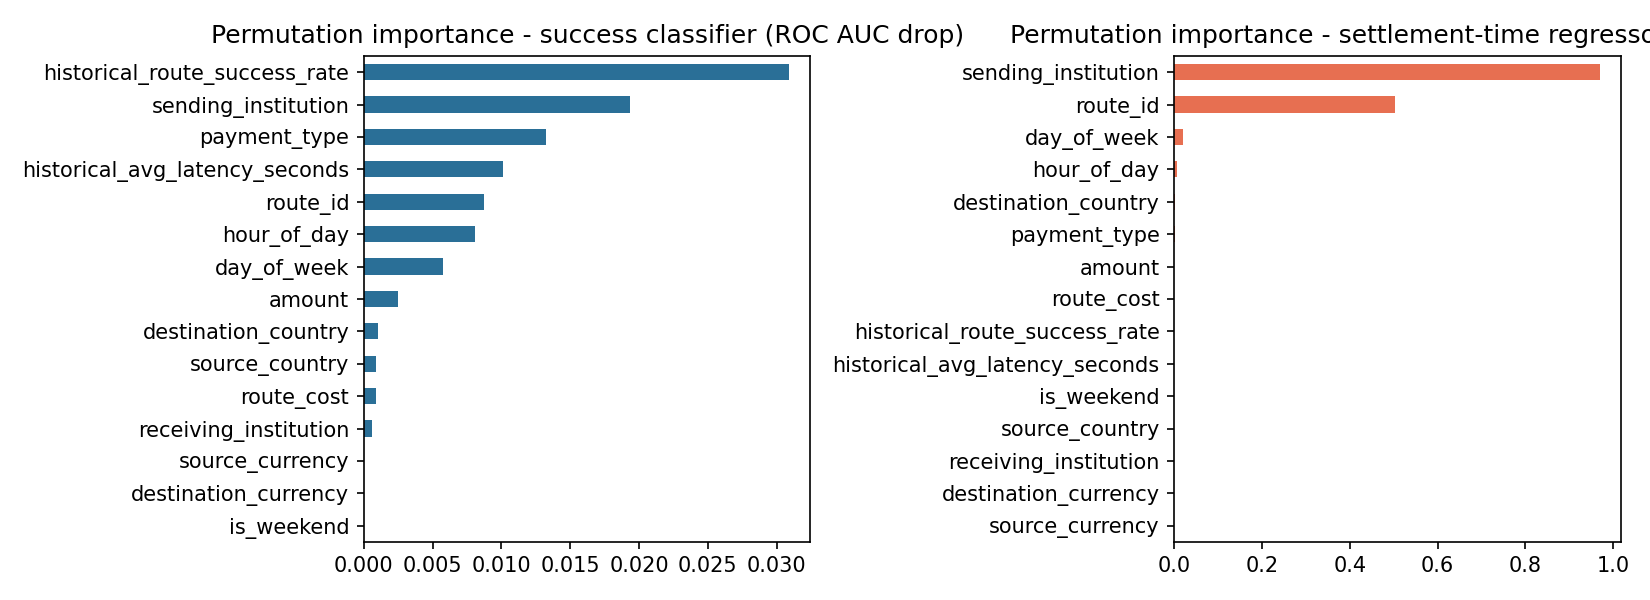

In [4]:
import train
m = train.main("../data.csv")
print("=== Prediction Goal 1: payment_success (test set) ===")
print(pd.DataFrame(m["classification"]).T.round(4).to_string())
print("Confusion matrix [[TN,FP],[FN,TP]]:", m["confusion_matrix"], "| tuned threshold:", round(m["decision_threshold"],3), "| expected calibration error:", round(m["expected_calibration_error"],4))
print("\n=== Prediction Goal 2: settlement_time_seconds, completed payments (test set) ===")
print(pd.DataFrame(m["regression_success_only"]).T.round(3).to_string())
print("\n=== Inference latency (quality requirement) ==="); print(json.dumps(m["latency"], indent=2))
print("\nModel version:", m["model_version"])

**Interpretation.** The target is generated probabilistically (success probabilities compressed between ~0.72 and ~0.98), so ROC-AUC ≈ 0.70 is close to the attainable ceiling – a perfect model cannot separate classes better than the underlying Bernoulli noise allows. What the decision engine actually consumes is the *probability*, and the reliability diagram shows it is very well calibrated (ECE ≈ 0.6%). The regressor explains ~94% of settlement-time variance and cuts MAE by ~38% versus simply using the route's historical average latency.

## 4. Prescription goal – the decision engine
Pure business logic (non-ML): applies hard constraints then either picks the highest success probability (*prediction* mode) or the best weighted success/latency/cost score (*optimisation* mode).

In [5]:
import joblib, numpy as np
from decision_engine import recommend, Constraints
clf = joblib.load("../artifacts/success_classifier.joblib"); reg = joblib.load("../artifacts/settlement_regressor.joblib")
routes = json.load(open("../artifacts/route_catalog.json"))
payment = {"source_country":"US","destination_country":"India","source_currency":"USD","destination_currency":"INR","amount":1500.0,"payment_type":"P2P","hour_of_day":2,"day_of_week":6,"is_weekend":1}
X = pd.DataFrame([{**payment, **r} for r in routes])[FEATURES]
cands = [{"route_id":r["route_id"],"sending_institution":r["sending_institution"],"receiving_institution":r["receiving_institution"],"route_cost":r["route_cost"],
          "predicted_success_probability":float(p),"predicted_settlement_seconds":float(t)} for r,p,t in zip(routes, clf.predict_proba(X)[:,1], np.expm1(reg.predict(X)))]
for mode, cons in [("prediction", None), ("optimisation", None), ("optimisation", Constraints(max_cost=2.0))]:
    res = recommend(cands, mode=mode, constraints=cons)
    print(f"[{mode}{' + max_cost=2.0' if cons else ''}] ->", res["explanation"])
    print(pd.DataFrame(res["ranked_routes"])[["route_id","predicted_success_probability","predicted_settlement_seconds","route_cost","score"]].round(3).to_string(index=False), "\n")

[prediction] -> ROUTE_B via Bank_B->Bank_Y: P(success)=95.6%, expected settlement 0.16 h, cost 5.00. Selected because it has the highest predicted success probability.
route_id  predicted_success_probability  predicted_settlement_seconds  route_cost  score
 ROUTE_B                          0.956                       575.371         5.0  0.956
 ROUTE_E                          0.920                      3491.779         3.5  0.920
 ROUTE_A                          0.877                      7094.271         1.5  0.877
 ROUTE_D                          0.863                     13866.485         2.0  0.863
 ROUTE_F                          0.801                     82646.409         1.0  0.801
 ROUTE_C                          0.770                    165395.912         0.5  0.770 

[optimisation] -> ROUTE_B via Bank_B->Bank_Y: P(success)=95.6%, expected settlement 0.16 h, cost 5.00. Selected because it has the best weighted trade-off of success, latency and cost.
route_id  predicted_su

## 5. Objective 2 – start the microservices and the event broker
Five independent OS processes: event broker (:8010), prediction service (:8001), decision service (:8002), API gateway (:8000), audit consumer (:8003).

In [6]:
import subprocess, sys, time, urllib.request
subprocess.run([sys.executable, "stop_all.py"], capture_output=True)
proc = subprocess.Popen([sys.executable, "run_all.py"], stdout=open("../artifacts/services.log","w"), stderr=subprocess.STDOUT, start_new_session=True)
time.sleep(10)
print(open("../artifacts/services.log").read())

[event-broker] listening on :8010  topics=['payment.requested', 'prediction.completed', 'route.recommended', 'service.error']
started event-broker         pid=13107  http://127.0.0.1:8010
[prediction-service] listening on http://127.0.0.1:8001
[prediction-service] 127.0.0.1 "GET /health HTTP/1.1" 200 -
started prediction-service   pid=13109  http://127.0.0.1:8001
[decision-service] listening on http://127.0.0.1:8002
[decision-service] 127.0.0.1 "GET /health HTTP/1.1" 200 -
started decision-service     pid=13111  http://127.0.0.1:8002
[api-gateway] listening on http://127.0.0.1:8000
[api-gateway] 127.0.0.1 "GET /health HTTP/1.1" 200 -
started api-gateway          pid=13113  http://127.0.0.1:8000
[audit-consumer] listening on http://127.0.0.1:8003
[audit-consumer] subscribed to ['payment.requested', 'prediction.completed', 'route.recommended', 'service.error'] group=audit
[audit-consumer] 127.0.0.1 "GET /health HTTP/1.1" 200 -
started audit-consumer       pid=13115  http://127.0.0.1:8003

## 6. End-to-end demonstration through the API gateway
The two requirements from the problem statement: **(1) prediction** – which route has the best predicted success; **(2) optimisation** – the best combined decision over success, latency and cost under business constraints.

In [7]:
import runpy; runpy.run_path("demo_client.py", run_name="__main__")


SCREENSHOT 1 - Health of all microservices (GET /services)
{
  "prediction-service": {
    "status": "ok",
    "service": "prediction-service",
    "time": 1791394237.0602553
  },
  "decision-service": {
    "status": "ok",
    "service": "decision-service",
    "time": 1791394237.061231
  },
  "event-broker": {
    "status": "ok",
    "service": "event-broker"
  }
}

SCREENSHOT 2 - Prediction service model info (GET :8001/model-info)
{
  "model_version": "v20261007-173026",
  "decision_threshold": 0.9100000000000003,
  "classifier_test_metrics": {
    "roc_auc": 0.6980394953774632,
    "brier": 0.07606625380842166,
    "log_loss": 0.274649988205375,
    "balanced_accuracy": 0.6395215285893934,
    "failure_recall": 0.6789554531490015,
    "accuracy": 0.6069333333333333,
    "precision": 0.9516091687890715,
    "recall": 0.6000876040297853,
    "f1": 0.7360315186246418
  },
  "regressor_test_metrics": {
    "mae_seconds": 4188.443592255337,
    "rmse_seconds": 9312.635947298146,
    "

## 7. Business impact on held-out data and latency measurement
For 300 unseen test transactions we compare the route the ML system recommends with the route actually used historically. Two weight profiles show the trade-off knob.

SCREENSHOT 11 - Business impact on 300 held-out test transactions, weights={'success': 0.6, 'latency': 0.25, 'cost': 0.15}
{
  "weights": {
    "success": 0.6,
    "latency": 0.25,
    "cost": 0.15
  },
  "transactions_evaluated": 300,
  "historical_route": {
    "expected_success_rate": 0.9073496738908743,
    "actual_success_rate": 0.9333333333333333,
    "expected_settlement_hours": 8.561293320369089,
    "avg_cost": 2.09
  },
  "ml_optimised_route": {
    "expected_success_rate": 0.9732846337793097,
    "expected_settlement_hours": 0.2397904020338808,
    "avg_cost": 4.498333333333333
  },
  "always_cheapest_heuristic": {
    "expected_success_rate": 0.8329788493909
  },
  "always_most_reliable": {
    "expected_success_rate": 0.9756041300690053,
    "avg_cost": 5.0
  },
  "uplift_vs_historical": {
    "success_rate_points": 6.593495988843545,
    "settlement_time_reduction_pct": 97.1991334362605,
    "cost_change_pct": 115.23125996810207
  },
  "route_changed_pct": 85.666666666666

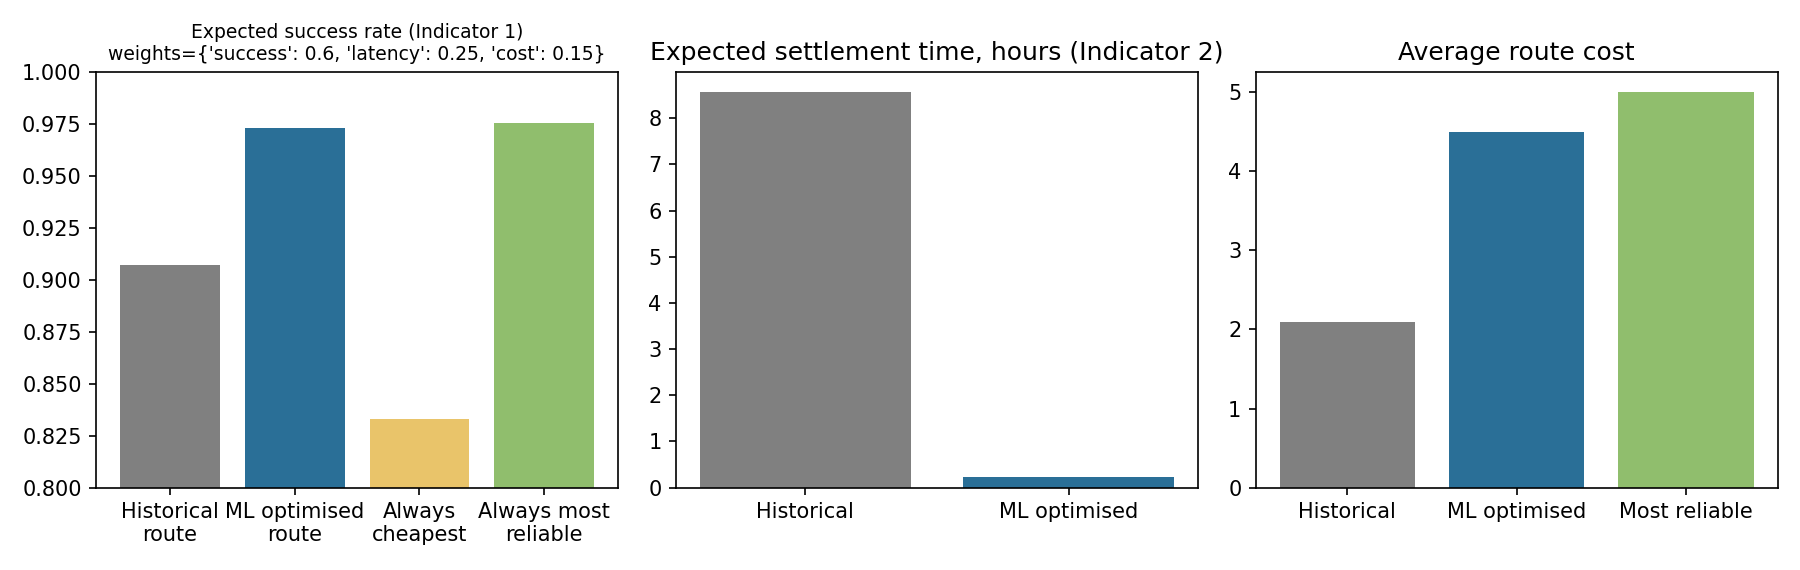

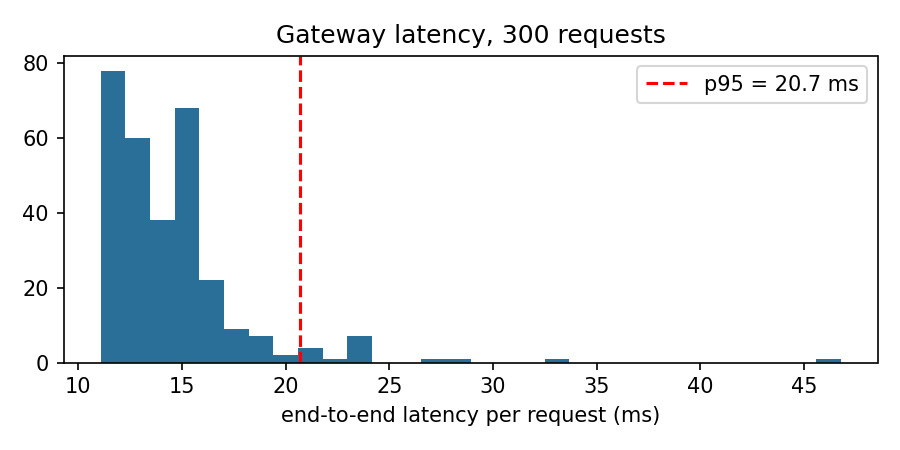

In [8]:
import runpy, sys
sys.argv = ["business_impact.py", "300"]; runpy.run_path("business_impact.py", run_name="__main__")

SCREENSHOT 11 - Business impact on 300 held-out test transactions, weights={'success': 0.4, 'latency': 0.2, 'cost': 0.4}
{
  "weights": {
    "success": 0.4,
    "latency": 0.2,
    "cost": 0.4
  },
  "transactions_evaluated": 300,
  "historical_route": {
    "expected_success_rate": 0.9073496738908743,
    "actual_success_rate": 0.9333333333333333,
    "expected_settlement_hours": 8.561293320369089,
    "avg_cost": 2.09
  },
  "ml_optimised_route": {
    "expected_success_rate": 0.9315914203618867,
    "expected_settlement_hours": 1.2356291012590888,
    "avg_cost": 1.5
  },
  "always_cheapest_heuristic": {
    "expected_success_rate": 0.8329788493909
  },
  "always_most_reliable": {
    "expected_success_rate": 0.9756041300690053,
    "avg_cost": 5.0
  },
  "uplift_vs_historical": {
    "success_rate_points": 2.4241746471012404,
    "settlement_time_reduction_pct": 85.56726121835739,
    "cost_change_pct": -28.229665071770327
  },
  "route_changed_pct": 81.66666666666667,
  "recommen

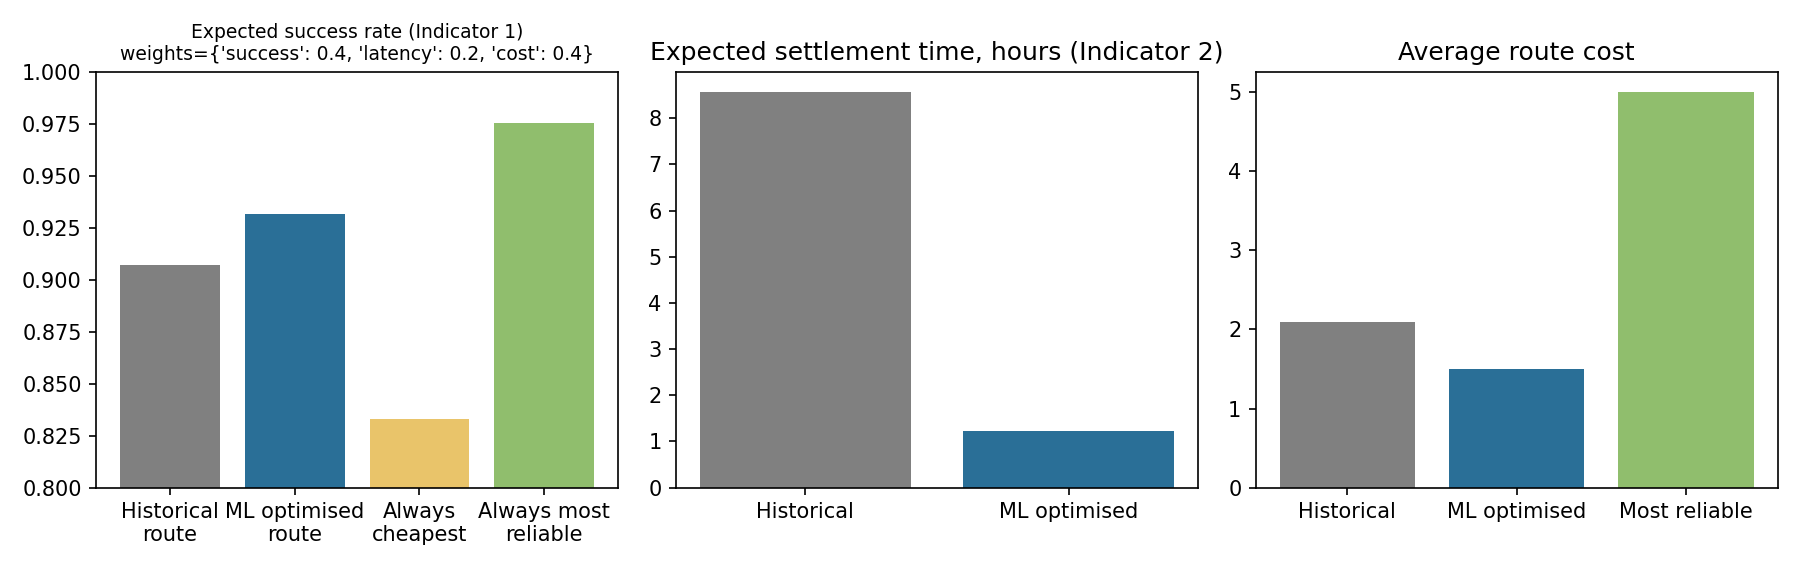

In [9]:
sys.argv = ["business_impact.py", "300", "0.4,0.2,0.4", "cost_aware"]; runpy.run_path("business_impact.py", run_name="__main__")

## 8. Fault isolation (microservices) and error events (event-driven)

In [10]:
runpy.run_path("fault_demo.py", run_name="__main__")

SCREENSHOT 12 - Fault isolation demo
1) Stopping prediction-service ...
   gateway /services -> {"prediction-service": {"status": "DOWN", "error": "<urlopen error [Errno 111] Connection refused>"}, "decision-service": {"status": "ok", "service": "decision-service", "time": 1791394249.307654}, "event-broker": {"status": "ok", "service": "event-broker"}} ...
2) Request while ML service is down -> {"http_status": 503, "error": "prediction service unavailable", "transaction_id": "FAULT_001"}
   service.error topic now has 1 event(s)
3) Restarting prediction-service ...
4) Request after recovery -> ROUTE_B P(success)=0.981 end_to_end_ms=20.1


## 9. Shut down

In [11]:
subprocess.run([sys.executable, "stop_all.py"])